# Machine Learning Project - Burnout risk level prediction


###### Author: Pinelli Gabriele

In [1]:
!pip install -r requirements.txt


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy.stats import loguniform
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_validate, RepeatedStratifiedKFold, learning_curve, validation_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.base import clone
from imblearn.pipeline import Pipeline as IMBPipeline
from imblearn.under_sampling import TomekLinks
import itertools

random_state = 96

## Dataset description
URL: https://www.kaggle.com/datasets/laveshjadon/ai-impact-on-students/data

The raw data collection describes the (recent-years) emerging phenomenon of Generative AI tool massive usage and its effects in a population of university students. It is composed by 50000 instances, 15 features with mixed data-types and the feature that will be our target ('Burnout_Risk_Level'), a 3-class feature. In particular the features are the following:
- **Student ID**: unique numeric identifier for each student [numerical-int]
- **Major_Category**: the student's field of study [categorical-nominal]
- **Year_of_Study**: the student academic standing [categorical-ordinal]
- **Pre_Semester_GPA**:  GPA score at the beginning of the semester [numerical-float]
- **Weekly_GenAI_Hours**: average hours per week spent using Generative AI tools [numerical-float]
- **Primary_Use_Case**: main purpose of the Generative AI tools usage [categorical-nominal]
- **Prompt_Engineering_Skill**: self-assessed proficiency in creating effective prompts [categorical-ordinal]
- **Tool_Diversity**: number of distinct AI tools used [numerical-int]
- **Paid_Subscription**: whether the student has a paid AI subscription [boolean]
- **Traditional_Study_Hours**: weekly hours spent by the student on traditional study methods [numerical-float]
- **Perceived_AI_Dependency**: self-assessed dependency on AI tools [categorical-ordinal]
- **Institutional_Policy**: whether AI usage is permitted by the university as institution [categorical-ordinal]
- **Anxiety_Level_During_Exams**: self-assessed exam anxiety score [numerical-int]
- **Post_Semester_GPA**: GPA score at the end of the semester [numerical-float]
- **Skill_Retention_Score**: score measuring how well students retained learned skills post-semester [numerical-float]
- **Burnout_Risk_Level** (our label): assessed burnout risk for the student [categorical-ordinal]

The dataset, as we can see, is composed by a mix of data describing features of the student both pre-semester and post-semester.

My objective for this project is to use supervised learning techniques to perform a 3-class classification using as label 'Burnout_Risk_Level'.

In [3]:
df_raw = pd.read_csv('data/ai_student_impact_dataset.csv')
df_raw

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,149996,Business,Senior,2.899,12.16,Copywriting/Drafting,Beginner,2,False,13.36,2,Allowed_With_Citation,2,3.584,66.16,High
49996,149997,STEM,Senior,2.870,2.51,Copywriting/Drafting,Intermediate,1,False,4.67,3,Actively_Encouraged,3,3.096,81.62,Medium
49997,149998,Business,Senior,3.177,15.87,Summarizing_Reading,Advanced,5,True,3.92,4,Allowed_With_Citation,5,3.605,97.21,High
49998,149999,Business,Junior,3.398,19.91,Debugging/Troubleshooting,Intermediate,5,False,7.10,5,Allowed_With_Citation,3,3.527,84.12,Medium


## Initial feature selection and missing data handling

In [4]:
# Lists to divide features by datatype
numerical_cols = ['Pre_Semester_GPA', 'Weekly_GenAI_Hours', 'Traditional_Study_Hours']
bool_cols = ['Paid_Subscription']
ordinal_cols = ['Year_of_Study', 'Prompt_Engineering_Skill', 'Tool_Diversity', 'Institutional_Policy']
nominal_cols = ['Major_Category', 'Primary_Use_Case']

df_raw['Paid_Subscription'] = df_raw['Paid_Subscription'].map({False : 0, True : 1})

In [5]:
for col in ordinal_cols:
    print(f'\n {col}:')
    print(df_raw[col].unique())


 Year_of_Study:
<StringArray>
['Senior', 'Junior', 'Freshman', 'Sophomore', 'Graduate']
Length: 5, dtype: str

 Prompt_Engineering_Skill:
<StringArray>
['Beginner', 'Advanced', 'Intermediate']
Length: 3, dtype: str

 Tool_Diversity:
[1 5 2 4 3]

 Institutional_Policy:
<StringArray>
['Allowed_With_Citation', 'Strict_Ban', 'Actively_Encouraged']
Length: 3, dtype: str


Readed-off the categorical ordinal features, we create the proper rankings for each of them. 'Tool_Diversity' have numerical values but we'll treat it as a categorical ordinal feature.

In [6]:
ordinal_ranks = {
    'Year_of_Study' : ['Freshman', 'Sophomore', 'Junior', 'Senior', 'Graduate'],
    'Prompt_Engineering_Skill' : ['Beginner', 'Intermediate', 'Advanced'],
    'Tool_Diversity' : ['1', '2', '3', '4', '5'],
    'Institutional_Policy' : ['Strict_Ban', 'Allowed_With_Citation', 'Actively_Encouraged']
}

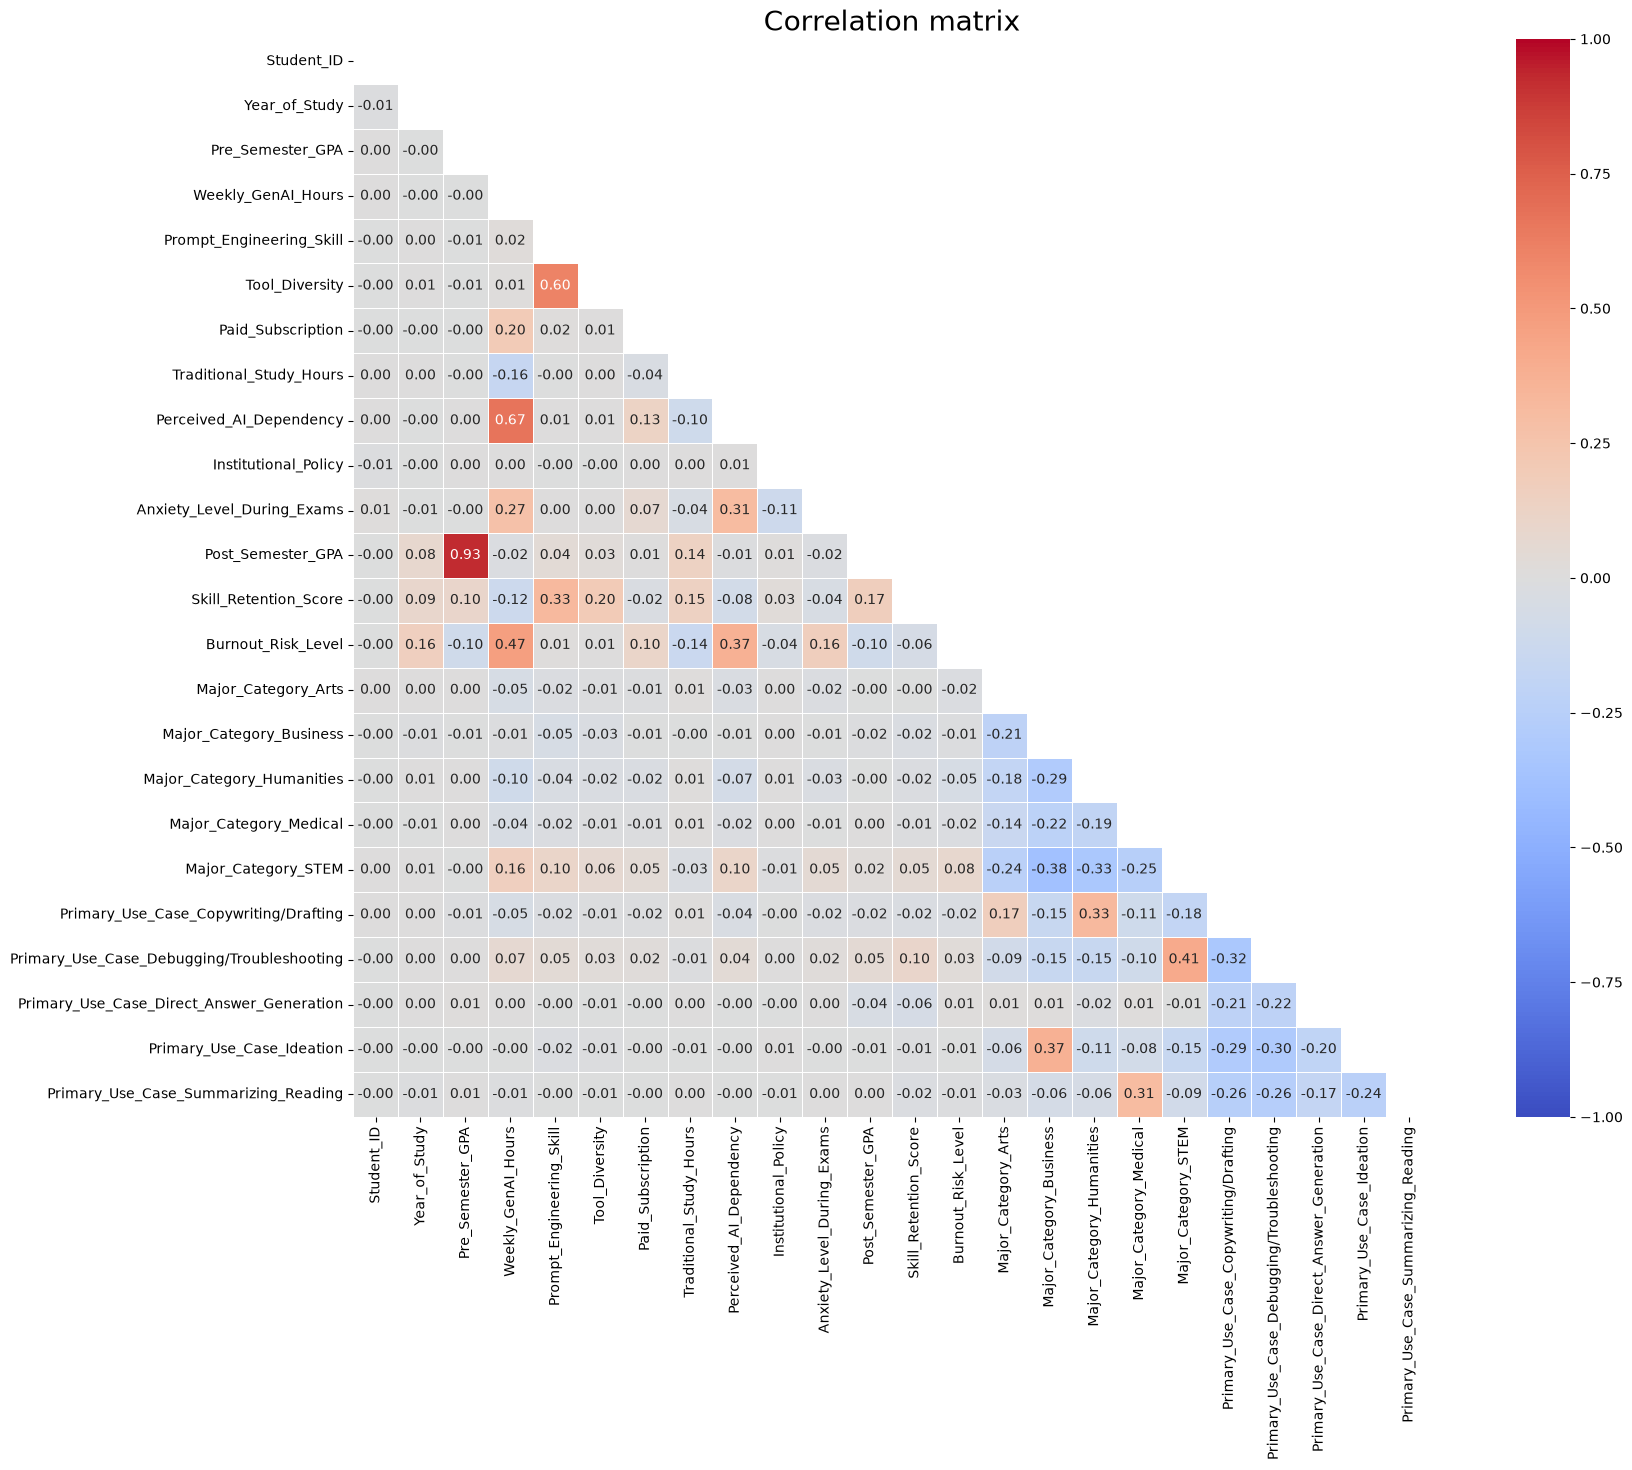

In [7]:
df4corr = df_raw.copy()

df4corr['Burnout_Risk_Level'] = df4corr['Burnout_Risk_Level'].map({'Low' : 0, 'Medium' : 1, 'High' : 2})

for col, ranks in ordinal_ranks.items():
    mapping = {val: i for i, val in enumerate(ranks)}
    df4corr[col] = df4corr[col].astype(str).map(mapping)

df4corr = pd.get_dummies(df4corr, columns=nominal_cols, drop_first=False)

features_to_analyze = df4corr.select_dtypes(include=['number', 'bool'])

corr = features_to_analyze.corr(method='pearson')
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(22, 14))
plt.title('Correlation matrix', fontsize=20)
sns.heatmap(corr, mask=mask, vmax=1.0, vmin=-1.0, center=0, annot=True, fmt=".2f", cmap='coolwarm', square=True, linewidths=.5)

plt.show()

Since we want to predict 'Burnout_Risk_Level' we can notice that some features are semantically related to it. As the purpose of the project is to create a ML pipeline that try to _predict_ burnout risk level we want to exclude all those features related to post-semester situation, because they are features which contain information not available in a real setting. We can also notice from the correlation matrix that between post-semester features there are some of them which are correlated with the target. Keeping them would expose the models to a data-leakage risk that might affect their performance and generalization capabilities.
We also drop the 'Student_ID' as it is a completely uninformative feature.

In [8]:
post_semester_cols = ['Post_Semester_GPA', 'Perceived_AI_Dependency', 'Anxiety_Level_During_Exams', 'Skill_Retention_Score']
X = df_raw.drop(columns=post_semester_cols+['Student_ID', 'Burnout_Risk_Level'])
y = df_raw['Burnout_Risk_Level'].map({'Low' : 0, 'Medium' : 1, 'High' : 2})

In [9]:
np.unique_counts(y)

UniqueCountsResult(values=array([0, 1, 2]), counts=array([16369, 21144, 12487]))

<Axes: xlabel='Burnout_Risk_Level', ylabel='Count'>

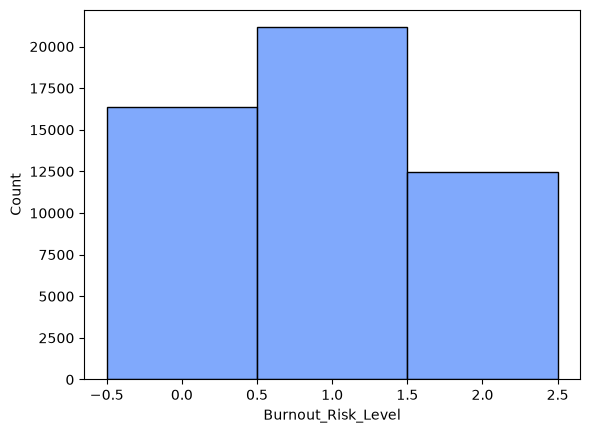

In [10]:
sns.histplot(y, discrete=True)

Classes are mildly imbalanced. We'll include in the configurations some methods to deal with class imbalance

## Stratified train-test split

Before analyzing numerical data, in order to do then a proper preprocessing without any leaked-information to the model, we perform a stratified train-test split that will guarantee us to work on 80% of the dataset in the training part and the remaining 20% in the final testing part. Stratification is essential for our dataset to keep the same proportion of labels in train and test data. Random state for reproducibility of results.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size= 0.2, stratify= y, random_state= random_state, shuffle= True)

## Data transformation pipeline

We start performing numerical features' analysis by extracting summary statistics

In [12]:
X_train[numerical_cols].describe()

,Pre_Semester_GPA,Weekly_GenAI_Hours,Traditional_Study_Hours
count,40000.000000,40000.000000,40000.000000
mean,3.144230,8.442067,11.211918
std,0.479789,8.264648,5.155742
min,1.183000,0.000000,1.000000
25%,2.828000,2.400000,7.570000
50%,3.208000,5.820000,11.190000
75%,3.520000,11.770000,14.700000
max,3.997000,40.000000,35.860000


We plot an histogram for each feature to visualize the distribution.

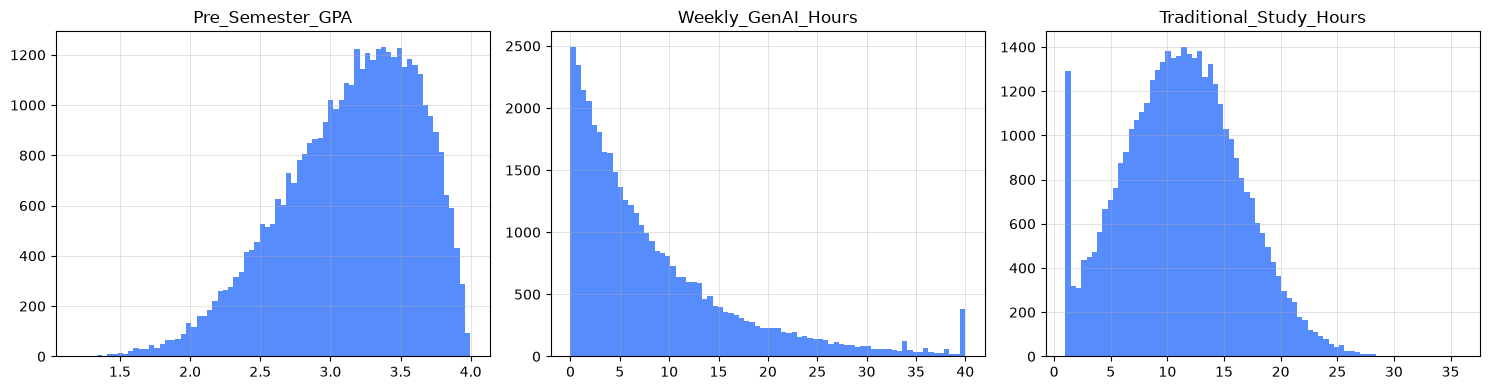

In [13]:
X_train[numerical_cols].hist(bins= 75, figsize= (15,4), layout= (1, 3))
plt.tight_layout()
plt.show()

'Pre_Semester_GPA' and 'Traditional_Study_Hours' show a bell-shaped (even if a bit skewed) distribution, so on them we could apply directly a standard scaling.
'Weekly_GenAI_Hours' is really strongly skewed, we also have to account for the fact that the distribution has a lot of the mass on a value near zero. So, before preprocessing we want to find a, preferably monotonic, transformation of the feature data that give us a more tractable distribution for our scaling purposes. Scale the features is essential for the well-functioning of some models in order to avoid dominance of some features in both loss computation and Euclidean distance.

We try to visualize the effect of applying a log(x+1) transformation to the feature 'Weekly_GenAI_Hours'.

In [14]:
X_train1 = X_train.copy()
X_train1['Weekly_GenAI_Hours_log'] = np.log1p(X_train1['Weekly_GenAI_Hours'])

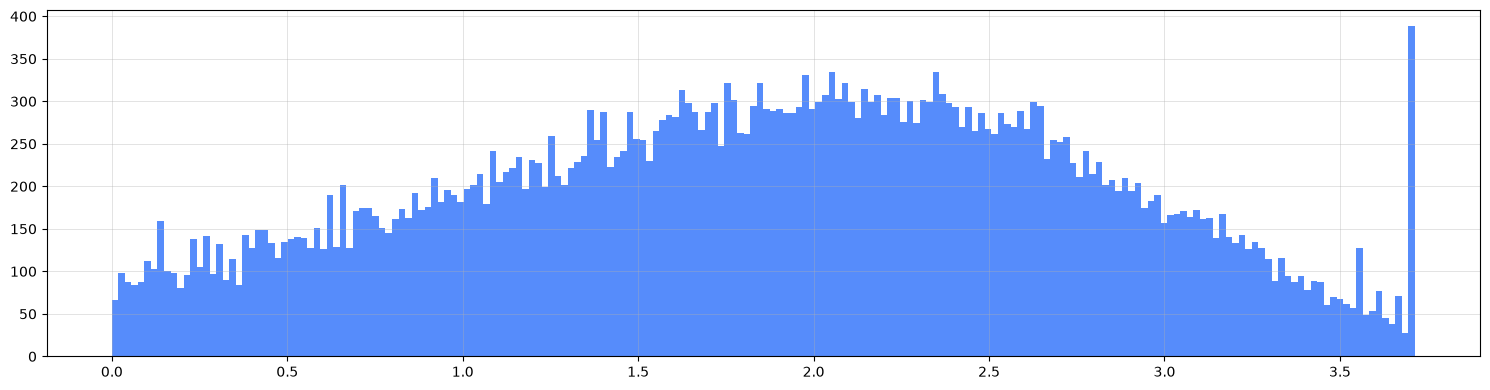

In [15]:
X_train1['Weekly_GenAI_Hours_log'].hist(bins=200, figsize= (15,4))
plt.tight_layout()
plt.show()

This transformation actually gives us a more tractable distribution (actually a bell-shaped distribution) to which we can apply a standardization.

## ColumnTransformers construction

The ColumnTransformer transforms properly data and accounts for:
    - The scaling of the numerical features
    - The encoding of categorical columns, divided into ordinal columns for which we use an OrdinalEncoder and nominal columns to which we apply a OneHotEncoder as there is no semantical order in their values
    - Preventing any column to accidentally fall into the dataset used then to feed the model configurations. To do this we set the parameter 'remainder' to the value 'drop'

This ColumnTransformer will be used for all the model configurations in order to provide them "optimized" data for their training, Random Forest included even though it is a model that is invariant to monotonic transformations (so numerical scaling wouldn't make almost any difference for its well-functioning).

In [16]:
log_scaling = Pipeline([
    ('log1p', FunctionTransformer(func= np.log1p, validate= True, feature_names_out='one-to-one')),
    ('scaler', StandardScaler())
])

ordinal_categories = [ordinal_ranks[c] for c in ordinal_cols]

colTransf = ColumnTransformer(
    transformers=[
        ('num_std', StandardScaler(), ['Pre_Semester_GPA', 'Traditional_Study_Hours']),
        ('num_log', log_scaling, ['Weekly_GenAI_Hours']),
        ('ordinal', OrdinalEncoder(categories=ordinal_categories), ordinal_cols),
        ('nominal', OneHotEncoder(drop= 'first', handle_unknown= 'ignore'), nominal_cols),
        ('bool', 'passthrough', bool_cols)
    ],
    remainder='drop',
    verbose_feature_names_out=False,
    sparse_threshold=0
)

## Model selection

Now we can focus on the definition and selection of the best model, which in the best configuration according to the metric chosen, will include:
- the column transformation
- the best method to handle imbalanced classes
- the best algorithm for dimensionality reduction
- the best classifier

This one will be the base model:

In [17]:
model_pipeline = IMBPipeline([
    ('trans', colTransf),
    ('sampler', None),
    ('dim_reduction', None),
    ('classifier', RandomForestClassifier(random_state= random_state))
])

To check that everything is working correctly we can run the methods fit and predict

In [18]:
model_pipeline.fit(X_train, y_train)

,steps,"[('trans', ...), ('sampler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](3,)","[0,1,2]"
feature_names_in_,"ndarray[object](10,)","['Major_Category','Year_of_Study','Pre_Semester_GPA',..., 'Paid_Subscription','Traditional_Study_Hours','Institutional_Policy']"
n_features_in_,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_std', ...), ('num_log', ...), ...]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False


In [19]:
pred_test = model_pipeline.predict(X_test)

We define the configurations since we have to test differet combinations of classification models, each with a different set of hyperparameters, dimensionality reduction technique and way to handle imbalanced classes.
For the sampler element we have one possible configuration besides the trivial "None" that is the one that uses TomekLinks. If chosen in one of the "winner" configurations, the Tomek Links sampler addresses the problem of imbalance as a separate technique from the classifier by eliminating the instances of the majority class of each pair of nearby instances that belong to different classes (i.e. Tomek Links).
Additionally, each classifier has its own "built-in" way to manage imbalanced classes, also these are considered hyperparameters to tune.
For the dimensionality reduction technique, excluding the trivial "None", we have a PCA with number of components to be chosen  by the random search.
For the classifier element, we have 3 concurrent models: KNN, a Logistic Regression and a Random Forest (all of them with hyperparameters to be tuned).

In [20]:
sampler_configs = [
    {'sampler' : [None]},
    {'sampler' : [TomekLinks()]}]

dim_reduction_configs = [
    {'dim_reduction' : [None]},
    {'dim_reduction' : [PCA(random_state=random_state)],
     'dim_reduction__n_components' : [0.5, 0.7, 0.9]
     }]

classifier_configs = [
    {
        'classifier' : [KNeighborsClassifier()],
        'classifier__n_neighbors' : [3, 5, 7, 9, 11, 15, 21],
        'classifier__weights' : ['uniform', 'distance']
     },
    {
        'classifier' : [LogisticRegression(solver= 'saga', max_iter= 1000, random_state= random_state)],
        'classifier__C' : loguniform(0.001, 100),
        'classifier__l1_ratio' : [0, 1], # 0--> L2, 1--> L1
        'classifier__class_weight' : [None, 'balanced']
    },
    {
        'classifier' : [RandomForestClassifier(random_state= random_state)],
        'classifier__n_estimators' : [50, 100, 200, 500]
    }
]

We want to check every possible combination [sampler, dim. reduction, classifier].
For these elements we have a sets of hyperparameters. To get the combinations we take the cartesian product between all elements we define for each component of the model. Then we chain the configuration elements listed in the extended cartesian product into a single dictionary to form the configuration compactly.

In [21]:
all_configs = [dict(itertools.chain(*(e.items() for e in config))) for config in itertools.product(sampler_configs, dim_reduction_configs, classifier_configs)]

In [22]:
print(all_configs)

[{'sampler': [None], 'dim_reduction': [None], 'classifier': [KNeighborsClassifier()], 'classifier__n_neighbors': [3, 5, 7, 9, 11, 15, 21], 'classifier__weights': ['uniform', 'distance']}, {'sampler': [None], 'dim_reduction': [None], 'classifier': [LogisticRegression(max_iter=1000, random_state=96, solver='saga')], 'classifier__C': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x11d581eb0>, 'classifier__l1_ratio': [0, 1], 'classifier__class_weight': [None, 'balanced']}, {'sampler': [None], 'dim_reduction': [None], 'classifier': [RandomForestClassifier(random_state=96)], 'classifier__n_estimators': [50, 100, 200, 500]}, {'sampler': [None], 'dim_reduction': [PCA(random_state=96)], 'dim_reduction__n_components': [0.5, 0.7, 0.9], 'classifier': [KNeighborsClassifier()], 'classifier__n_neighbors': [3, 5, 7, 9, 11, 15, 21], 'classifier__weights': ['uniform', 'distance']}, {'sampler': [None], 'dim_reduction': [PCA(random_state=96)], 'dim_reduction__n_components': [0.5, 0.7, 

In [23]:
print(f'Number of configs: {len(all_configs)}')

Number of configs: 12


Now that we have the configurations we use nested cross-validation to identify the best 5 models based on F1 Macro metric.
We choose F1 Macro because it is the arithmetic mean of the individual F1 scores of each class, so it assigns equal importance to the three classes. By treating all classes equally, F1 Macro prevents the majority classes from dominating the metric giving then to the minority class a higher relative weight compared to standard accuracy. This can be potentially beneficial for our prediction model in a semantic way: predicting well the minority class, which is 'High' risk level of burnout, can make the model more useful for practical applications in trying to prevent burnout in students.
Back to the nested cross validation we have:
- the inner loop that uses a randomized grid search to perform hyperparameter optimization
- the outer loop that performs cross-validation using the hyperparameter configuration founded in the inner loop

In [24]:
randomSearch = RandomizedSearchCV(
    model_pipeline,
    param_distributions= all_configs,
    n_iter= len(all_configs) * 5,
    n_jobs= -1,
    cv= 2,
    scoring='f1_macro',
    random_state= random_state,
    error_score= 'raise'
)

In [25]:
scores = cross_validate(
    randomSearch,
    X_train, y_train,
    scoring= 'f1_macro',
    cv = 5,
    return_estimator= True,
    verbose= 3
)

[CV] END ......................................., score=0.519 total time= 1.5min
[CV] END ......................................., score=0.524 total time= 1.5min
[CV] END ......................................., score=0.524 total time= 1.3min
[CV] END ......................................., score=0.528 total time= 1.2min
[CV] END ......................................., score=0.532 total time= 1.2min


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:  6.7min finished


We now print the models that score higher in F1 Macro and their parameters

In [26]:
for idx, estim in enumerate(scores['estimator']):
    print(f'\n Sampler: {estim.best_estimator_.get_params()['sampler']}')
    print(f'\n Dim. Reduction: {estim.best_estimator_.get_params()['dim_reduction']}')
    print(f'\n Classifier: {estim.best_estimator_.get_params()['classifier']} \n with parameters \n {estim.best_estimator_.get_params()['classifier'].get_params()}')
    print(f'\n Score (Macro F1): {scores['test_score'][idx]}')
    print('-' * 50)


 Sampler: None

 Dim. Reduction: None

 Classifier: LogisticRegression(C=np.float64(0.027780599040579102), l1_ratio=0,
                   max_iter=1000, random_state=96, solver='saga') 
 with parameters 
 {'C': np.float64(0.027780599040579102), 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0, 'max_iter': 1000, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': 96, 'solver': 'saga', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}

 Score (Macro F1): 0.5190366398104982
--------------------------------------------------

 Sampler: None

 Dim. Reduction: None

 Classifier: LogisticRegression(C=np.float64(0.040751556555907884), l1_ratio=1,
                   max_iter=1000, random_state=96, solver='saga') 
 with parameters 
 {'C': np.float64(0.040751556555907884), 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 1, 'max_iter': 1000, 'n_jobs': None, 'penalty': 'deprecated', 'random_state'

On F1 Macro score, Logistic Regression win all the "top 5 places".
We can notice that:
- none of the chosen configurations selected TomekLinks or PCA. These tools seem not to help Logistic Regression in getting a higher F1 Macro score
- class_weight hyperparameter has never been picked in any of the winning configurations. Either this hyperparameter seems not to help Logistic Regression in F1 Macro
- in all 5 configurations we have a strong regularization with C in the order of magnitude of $3*10^{-2}$ (and 3 model configurations out of 5 preferring L1 regularization versus L2 one)

## Final predictive model configuration

Grounding on the explicit result of the nested cross-validation we define the best model pipeline as

In [27]:
best_model_pipeline = IMBPipeline([
    ('trans', colTransf),
    ('classifier', LogisticRegression(solver= 'saga', max_iter= 1000, random_state= random_state))
])

We want to perform a further RandomSearchCV with a RepeatedStratifiedKFold to tune the best configuration and find the best hyperparameter setting according to F1 Macro. So we define the parameter space in which the random search will operate, knowing that the range for the optimal value of C hyperparameter is around $10^{-2}$ + knowing that only 3 out of 5 winning configuration picked L1 regularization, so we keep the type of regularization as hyperparameter too.

In [28]:
params = {
    'classifier__C' : loguniform(0.005, 0.15),
    'classifier__l1_ratio' : [0, 1]
}

In [29]:
best_randomSearch = RandomizedSearchCV(
    estimator=best_model_pipeline,
    param_distributions=params,
    cv= RepeatedStratifiedKFold(n_splits=5, n_repeats= 3, random_state= random_state),
    n_iter= 20,
    scoring= 'f1_macro',
    n_jobs= -1,
    random_state= random_state,
    verbose= 2
)

In [30]:
best_randomSearch.fit(X_train, y_train)

Fitting 15 folds for each of 20 candidates, totalling 300 fits
[CV] END classifier__C=0.010377400337980826, classifier__l1_ratio=0; total time=   0.7s
[CV] END classifier__C=0.010377400337980826, classifier__l1_ratio=0; total time=   0.7s
[CV] END classifier__C=0.010377400337980826, classifier__l1_ratio=0; total time=   0.8s
[CV] END classifier__C=0.010377400337980826, classifier__l1_ratio=0; total time=   0.8s
[CV] END classifier__C=0.010377400337980826, classifier__l1_ratio=0; total time=   0.7s
[CV] END classifier__C=0.010377400337980826, classifier__l1_ratio=0; total time=   0.8s
[CV] END classifier__C=0.010377400337980826, classifier__l1_ratio=0; total time=   0.8s
[CV] END classifier__C=0.010377400337980826, classifier__l1_ratio=0; total time=   0.7s
[CV] END classifier__C=0.010377400337980826, classifier__l1_ratio=0; total time=   0.5s
[CV] END classifier__C=0.010377400337980826, classifier__l1_ratio=0; total time=   0.5s
[CV] END classifier__C=0.010377400337980826, classifier__

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ver='saga'))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__C': <scipy.stats....t 0x11acf95e0>, 'classifier__l1_ratio': [0, 1]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",RepeatedStrat...ndom_state=96)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",96
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``

In [31]:
print(f'Best mean CV F1 Macro: {best_randomSearch.best_score_: .4f}')
print(f'Best hyperparameters: {best_randomSearch.best_params_}')
best_randomSearch.best_estimator_

Best mean CV F1 Macro:  0.5251
Best hyperparameters: {'classifier__C': np.float64(0.02838792998853777), 'classifier__l1_ratio': 1}


,steps,"[('trans', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](3,)","[0,1,2]"
feature_names_in_,"ndarray[object](10,)","['Major_Category','Year_of_Study','Pre_Semester_GPA',..., 'Paid_Subscription','Traditional_Study_Hours','Institutional_Policy']"
n_features_in_,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_std', ...), ('num_log', ...), ...]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False


In [32]:
cls = best_randomSearch.best_estimator_

Having the best fine tuned model, we can now use it on test data and then do some analyses on its predictions.

In [33]:
y_test_pred = cls.predict(X_test)

## Learning curve

We now visualize learning curve in order to see how the performance of the final model changes with the size of the training set

In [34]:
train_sizes, train_scores, test_scores = learning_curve(
    cls,
    X= X_train,
    y= y_train,
    train_sizes=[0.01, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    cv= 5,
    n_jobs= -1,
    scoring= 'f1_macro',
    shuffle= False
)

In [35]:
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

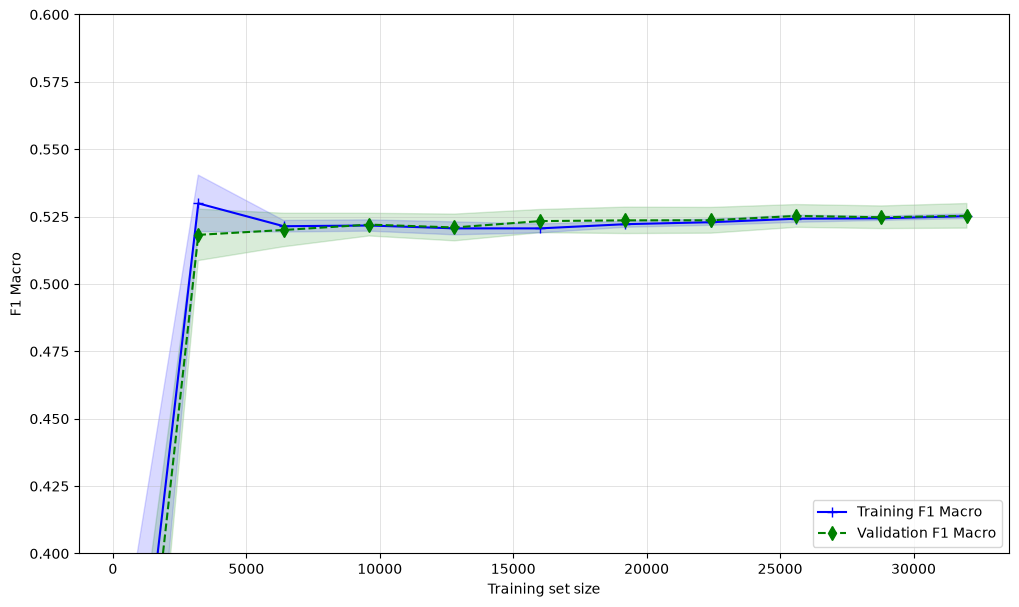

In [36]:
fig = plt.figure(figsize=(12,7))
ax = fig.add_subplot()

ax.plot(train_sizes, train_mean, color='blue', marker= '+', markersize= 7, label='Training F1 Macro')
ax.fill_between(train_sizes, train_mean + train_std, train_mean - train_std, color='blue', alpha=0.15)
ax.plot(train_sizes, test_mean, color= 'green', linestyle= '--', marker='d', markersize= 7, label='Validation F1 Macro')
ax.fill_between(train_sizes, test_mean + test_std, test_mean - test_std, color='green', alpha=0.15)

ax.grid()
ax.set_xlabel('Training set size')
ax.set_ylabel('F1 Macro')
ax.legend(loc='lower right')
ax.set_ylim((0.40, 0.60))
plt.show()

We can see from the learning curve that trainin and validation curves, after ~6000 samples, remain close to each other and inside the tight shaded bands in a plateau that continues until the maximum training set size. We can say that the model is underfitting, having high bias and quite low variance. After the point of ~5000 samples keeps a similar F1 Macro performance on both train and validation. In conclusion, having more data won't help reduce the bias with this model and this set of features

## Validation curve

Then we visualize the validation curve to see how the log-magnitude of the hyperparameter C influences the performance of the final model.

In [37]:
cls_valcurve = clone(cls) # Need cloning due to an error about reached max iter
cls_valcurve.set_params(classifier__max_iter=5000)

,steps,"[('trans', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_std', ...), ('num_log', ...), ...]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transfo

We take a wide range of C values

In [38]:
range_C = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 10, 100]
train_scores_c, test_scores_c = validation_curve(
    cls_valcurve,
    X= X_train,
    y= y_train,
    param_range= range_C,
    param_name='classifier__C',
    cv= 5,
    n_jobs= -1,
    scoring= 'f1_macro'
)

In [39]:
train_mean_c = np.mean(train_scores_c, axis=1)
train_std_c = np.std(train_scores_c, axis=1)
test_mean_c = np.mean(test_scores_c, axis=1)
test_std_c = np.std(test_scores_c, axis=1)

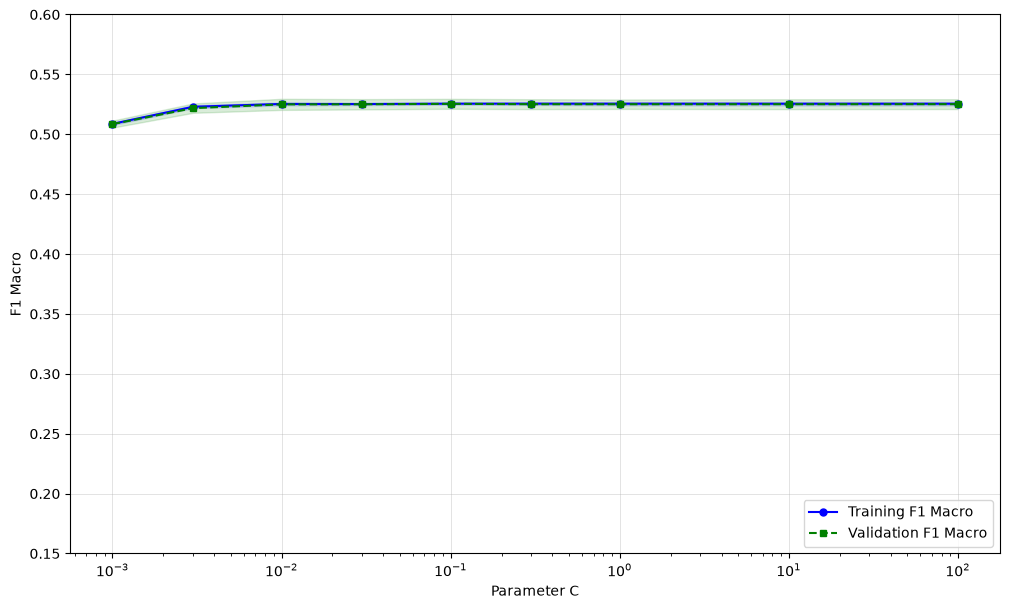

In [40]:
fig = plt.figure(figsize=(12,7))
ax = fig.add_subplot()

ax.plot(range_C, train_mean_c, color='blue', marker= 'o', markersize= 5, label='Training F1 Macro')
ax.fill_between(range_C, train_mean_c + train_std_c, train_mean_c - train_std_c, color='blue', alpha=0.15)
ax.plot(range_C, test_mean_c, color= 'green', linestyle= '--', marker='s', markersize= 5, label='Validation F1 Macro')
ax.fill_between(range_C, test_mean_c + test_std_c, test_mean_c - test_std_c, color='green', alpha=0.15)

ax.grid()
ax.set_xlabel('Parameter C')
ax.set_ylabel('F1 Macro')
ax.legend(loc='lower right')
ax.set_ylim((0.15, 0.60))
ax.set_xscale('log')
plt.show()

We can see that the validation curve is consistent with the cross-validation-picked C = 0.028 as tuned value for the hyperparameter. From $10^{-2}$ starts the plateau of the validation curve and the two curves seems almost indistinguishable for the whole upper range of the parameter C, so performance stays essentally the same. For values of C < $10^{-2}$ we can see that the classifier scores a bit low, probably as an effect of the strong regularization applied.

## Confusion Matrices and error analysis

We construct 2 confusion matrices with the objective of reasoning about the correct/wrong classifications of the best model configuration (with respect to F1 Macro)

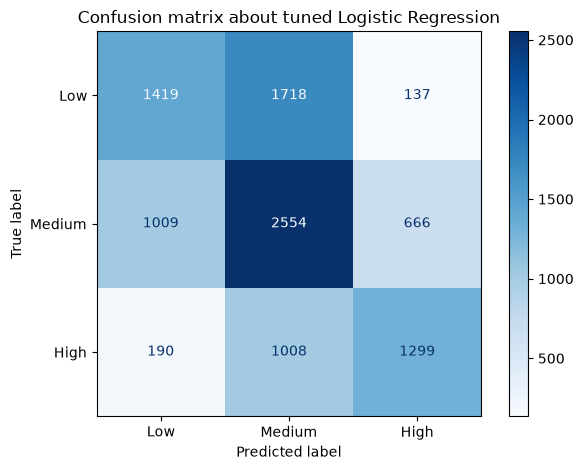

In [41]:
class_names = ['Low', 'Medium', 'High']
ConfusionMatrixDisplay.from_estimator(cls, X_test, y_test, display_labels=class_names, cmap='Blues')
plt.title('Confusion matrix about tuned Logistic Regression')
plt.tight_layout()
plt.show()

From the confusion matrix we can notice that:
- 'Low' class is highly misclassified as 'Medium'
- 'High' is the class that the model mostly tend to classify correctly (in fact it has the highest precision value)
- From the off diagonal terms (center excluded obviously) we can see that 'Low' and 'High' are rarely misclassified with each other by the model.
The problem for the model could be that the ordering of the labels plays a significant role in "adjacent" misclassification with respect to 'Medium'

In [42]:
print(classification_report(y_test, y_test_pred, labels=[0,1,2], digits=4))

              precision    recall  f1-score   support

           0     0.5420    0.4334    0.4817      3274
           1     0.4837    0.6039    0.5372      4229
           2     0.6180    0.5202    0.5649      2497

    accuracy                         0.5272     10000
   macro avg     0.5479    0.5192    0.5279     10000
weighted avg     0.5363    0.5272    0.5259     10000



Now we construct a normalized confusion matrix, marginalizing over rows (so, true labels), in order to visualize better "where" samples are mostly misclassified.

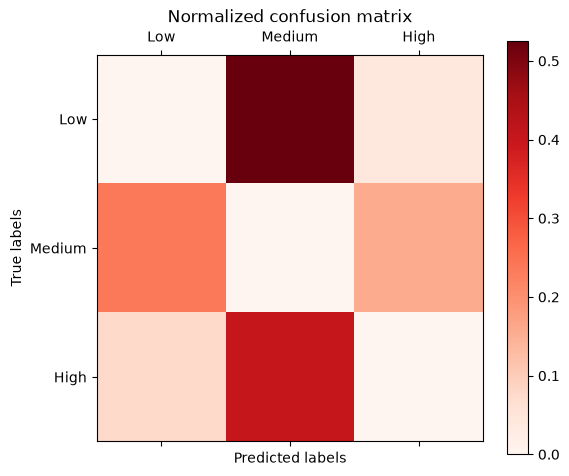

In [43]:
conf_matrix = confusion_matrix(y_test, y_test_pred, labels=[0,1,2])
row_sums = conf_matrix.sum(axis=1, keepdims=True) # Row maginal aka support of each row
norm_conf_matrix = conf_matrix / row_sums
np.fill_diagonal(norm_conf_matrix, 0) # Remove the diagonal elements to visualize the matrix better

fig, ax = plt.subplots(figsize= (6,5))
im = ax.matshow(norm_conf_matrix, cmap= 'Reds')
ax.set_xticks(range(len(class_names)))
ax.set_yticks(range(len(class_names)))
ax.set_xticklabels(class_names)
ax.set_yticklabels(class_names)
ax.set_xlabel('Predicted labels')
ax.set_ylabel('True labels')
ax.set_title('Normalized confusion matrix')
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

This normalized confusion matrix let us see clearly, and also generalize to all the labels, the hypothesis made above: the model misclassifies labels especially when the predicted and the true label are "adjacent" to each other and so the 'Medium' class seems to "attract" the most misclassifications.
In conclusion the best model, considering F1 Macro as metric, is not completely bad at classifying samples but there is evidence in the predictions that advancements in classification performance could potentially be achieved if the ordering of the labels is tackled as a real part of the classification problem.